# Week 6 · Topic 4 — Apply, Lambda and Finishing Up

**Box we are building: STORE + PROCESS, the whole job**

A `lambda` is a `def` you don't bother naming, for a one-line function you are
only going to use once — usually right inside `.apply()`.

> **Already know this?** Skip to the *Topic 4 Challenge*.

---
## 1. `.apply()` runs a function on every value in a column

Start with a normal function, the way Week 3 taught it.

In [ ]:
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100

def classify(percent):
    if percent >= 100:
        return "OVER LIMIT"
    elif percent >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

### Your turn
Write your own single-argument function and `.apply()` it to the `used` column.

In [3]:
# your code here
import pandas as pd

servers = pd.DataFrame({
    "hostname": ["srv-01", "srv-02", "srv-03", "srv-04", "srv-05", "srv-06"],
    "region": ["north", "south", "east", "west", "west", "south"],
    "used": [120, 450, 300, 85, 500, 45],       
    "total": [100, 500, 100, 250, 100, 100],     
})
servers["percent"] = (servers["used"] / servers["total"]) * 100

def classify(percent):
    if percent >= 100:
        return "OVER LIMIT"
    elif percent >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

  hostname region  used  total  percent      status
0   srv-01  north   120    100    120.0  OVER LIMIT
1   srv-02  south   450    500     90.0     WARNING
2   srv-03   east   300    100    300.0  OVER LIMIT
3   srv-04   west    85    250     34.0          OK
4   srv-05   west   500    100    500.0  OVER LIMIT
5   srv-06  south    45    100     45.0          OK


---
## 2. `lambda` - the same idea, written inline

`lambda parameters: expression` — that IS the whole function. Only one
expression allowed — no `if`/`elif`/`else` statements, no loops.

In [ ]:
double = lambda x: x * 2
print(double(21))     # 42 - same as def double(x): return x * 2

```
def classify(p):                    lambda p: (
    if p >= 100:                        "OVER LIMIT" if p >= 100
        return "OVER LIMIT"             else "WARNING" if p >= 90
    elif p >= 90:                       else "OK"
        return "WARNING"             )
    else:
        return "OK"

same logic, same result - a block of statements vs one expression
```

### Your turn
Write `classify` as a lambda with a chained conditional, and check it gives the same result as the `def` version for every row.

In [ ]:
# your code here
import pandas as pd

servers = pd.DataFrame({
    "hostname": ["srv-01", "srv-02", "srv-03", "srv-04", "srv-05", "srv-06"],
    "region": ["north", "south", "east", "west", "west", "south"],
    "used": [120, 450, 300, 85, 500, 45],       
    "total": [100, 500, 100, 250, 100, 100],     
})
servers["percent"] = (servers["used"] / servers["total"]) * 100

classify = lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

  hostname region  used  total  percent      status
0   srv-01  north   120    100    120.0  OVER LIMIT
1   srv-02  south   450    500     90.0     WARNING
2   srv-03   east   300    100    300.0  OVER LIMIT
3   srv-04   west    85    250     34.0          OK
4   srv-05   west   500    100    500.0  OVER LIMIT
5   srv-06  south    45    100     45.0          OK


---
## 3. `.apply()` with a lambda, and `sort_values(key=...)`

lambda earns its place exactly here — a function small enough to write inline,
used exactly once, right where it is needed.

In [ ]:
servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(servers.sort_values("hostname", key=lambda col: col.str.lower()))

### Your turn
Use `.apply()` with a lambda to add a column `region_upper` — the `region` column, in capitals.

In [6]:
# your code here
servers["region_upper"] = servers["region"].apply(lambda ru: ru.upper())
print(servers)

  hostname region  used  total  percent      status region_upper
0   srv-01  north   120    100    120.0  OVER LIMIT        NORTH
1   srv-02  south   450    500     90.0     WARNING        SOUTH
2   srv-03   east   300    100    300.0  OVER LIMIT         EAST
3   srv-04   west    85    250     34.0          OK         WEST
4   srv-05   west   500    100    500.0  OVER LIMIT         WEST
5   srv-06  south    45    100     45.0          OK        SOUTH


---
## 4. Summarising, saving, and a first chart

`describe()` for a quick overview, `.to_csv()` to save, and one chart — straight
off a DataFrame. In a notebook, calling `.plot()` shows the chart inline.

Matplotlib is building the font cache; this may take a moment.


             used       total    percent
count    6.000000    6.000000    6.00000
mean   250.000000  191.666667  181.50000
std    195.524934  162.532048  183.31803
min     45.000000  100.000000   34.00000
25%     93.750000  100.000000   56.25000
50%    210.000000  100.000000  105.00000
75%    412.500000  212.500000  255.00000
max    500.000000  500.000000  500.00000


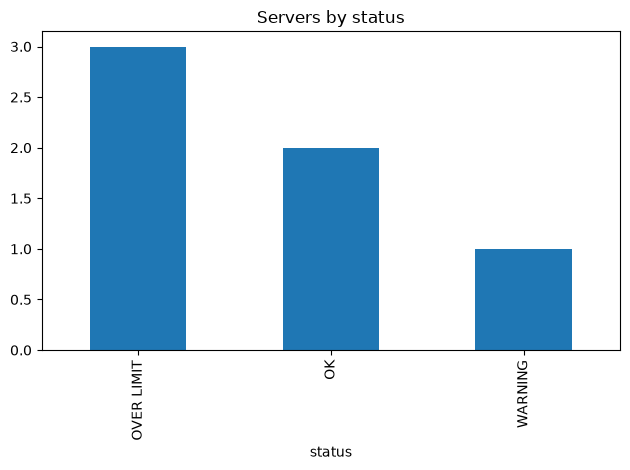

In [8]:
import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()

### Your turn
Make a bar chart of servers per region instead of per status.

             used       total    percent
count    6.000000    6.000000    6.00000
mean   250.000000  191.666667  181.50000
std    195.524934  162.532048  183.31803
min     45.000000  100.000000   34.00000
25%     93.750000  100.000000   56.25000
50%    210.000000  100.000000  105.00000
75%    412.500000  212.500000  255.00000
max    500.000000  500.000000  500.00000


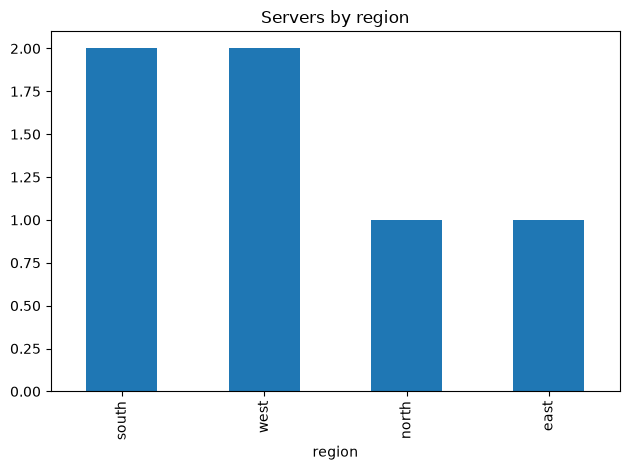

In [9]:
# your code here
print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["region"].value_counts().plot(kind="bar", title="Servers by region")
plt.tight_layout()
plt.show()

---
## Topic 4 Challenge

Load `servers.csv`, add `percent` and `status` (via `.apply()` with a lambda),
save the result to a new CSV, and produce one bar chart of the status counts.

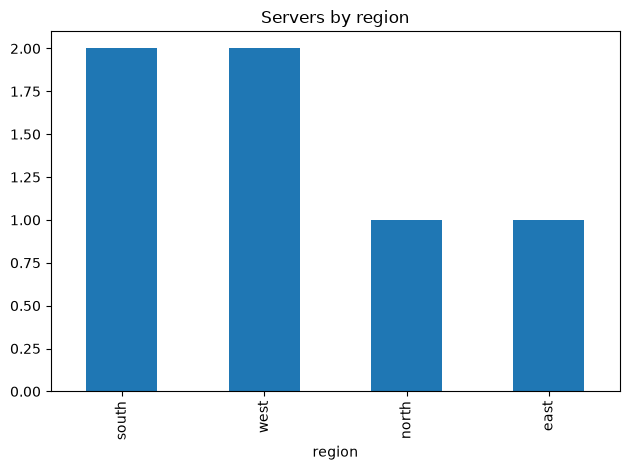

In [14]:
# your code here
import pandas as pd
import matplotlib.pyplot as plt

servers = pd.read_csv("servers.csv")

servers["percent"] = (servers["used"] / servers["total"]) * 100

servers["status"] = servers["percent"].apply(lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK")

servers.to_csv("servers_new.csv", index=False)

servers["region"].value_counts().plot(kind="bar", title="Servers by region")
plt.tight_layout()
plt.show()

---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | `df["clean_text"] = df["text"].apply(lambda t: t.strip().lower())` |
| **Cyber Security** | `df["flag"] = df["failed"].apply(lambda n: n >= 3)` |
| **IT** | `df.sort_values("hostname", key=lambda c: c.str.lower())` |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| a lambda with an `if` statement (not an expression) | `SyntaxError` | lambda only allows one expression — use chained `if/else`, or write a `def` |
| reusing the same lambda logic in three places | works, but repeats the logic three times | that is the sign you wanted a named function, not a lambda |
| forgetting `.apply()` and just writing `column.classify()` | `AttributeError` | `.apply(function)` runs your function on every value — the function itself is not a method on the column |
| calling `.plot()` in a plain script and seeing nothing | no chart appears | add `plt.show()` (script) — a notebook shows it automatically |

## Go deeper

`examples/01_apply_and_lambda.py` — apply, lambda syntax, chained conditionals, sort key
`examples/02_summarizing_saving_and_charting.py` — describe, to_csv, a first chart

---
## Recap

| You can now | Using |
|---|---|
| apply a function to a whole column | `column.apply(function)` |
| write a small inline function | `lambda x: expression` |
| choose lambda vs a named function | one-line, used once → lambda; reused or complex → `def` |
| get a quick overview | `.describe()` |
| save a result | `.to_csv(path, index=False)` |
| chart straight from a DataFrame | `.plot(kind=...)` |

**You now have all of CW1's toolkit.** Your mini-project this week closes it out.